# Lab 9 · Vision-based cognitive assistants
**UCS420 · Cognitive Computing**

The first assistant turns a photographed label into a readable transcript and a short field list. The second detects a face, classifies its visible expression and offers a follow-up the person can accept or ignore. Run the cells in order after completing the [setup](README.md).

In [1]:
from pathlib import Path
import hashlib
import os
import re
import subprocess

import cv2
import numpy as np
import requests
from IPython.display import display
from PIL import Image, ImageOps

LABEL = Path("examples/demo-label.png")
PORTRAIT = Path("examples/astronaut.png")

def load_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")

## 1 · Read a medicine bottle label
Crop to the label so the text fills the frame. The reader enlarges small text, converts it to grayscale and runs English OCR. It preserves the transcript and copies values from explicitly labeled lines. Curved bottles, glare and decimal points deserve particular attention. Compare the transcript with the printed label before using any medicine information.

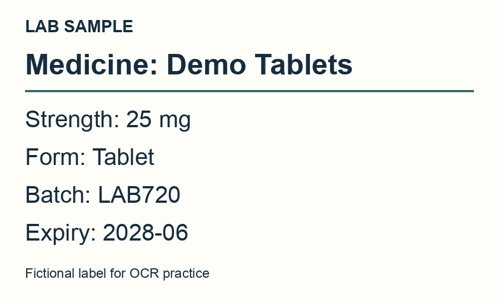

LAB SAMPLE

Medicine: Demo Tablets
Strength: 25 mg

Form: Tablet

Batch: LAB720

Expiry: 2028-06

Fictional label for OCR practice

Medicine  Demo Tablets
Strength  25 mg
Form      Tablet
Batch     LAB720
Expiry    2028-06


In [2]:
def read_label(image):
    gray = ImageOps.autocontrast(ImageOps.grayscale(image))
    scale = min(2, 2000 / max(gray.size))
    gray = gray.resize(tuple(max(1, round(x * scale)) for x in gray.size))
    ok, png = cv2.imencode(".png", np.asarray(gray))
    if not ok:
        raise ValueError("Could not encode label image.")
    run = subprocess.run(
        ["tesseract", "stdin", "stdout", "-l", "eng", "--psm", "6"],
        input=png.tobytes(), capture_output=True, check=True, timeout=60,
    )
    return run.stdout.decode("utf-8").strip()

field_names = {
    "Medicine": ("medicine", "drug name", "product name"),
    "Strength": ("strength",),
    "Form": ("form", "dosage form"),
    "Batch": ("batch", "lot"),
    "Expiry": ("expiry", "expiration", "exp"),
}

def label_fields(text):
    values = {}
    for field, aliases in field_names.items():
        prefix = "|".join(aliases)
        matches = re.findall(rf"^(?:{prefix})[ \t]*[:\-][ \t]*(\S[^\n]*)$",
                             text, re.IGNORECASE | re.MULTILINE)
        values[field] = matches[0].strip() if len(matches) == 1 else None
    return values

label_image = load_rgb(LABEL)
display(ImageOps.contain(label_image, (500, 300)))
transcript = read_label(label_image)
print(transcript or "No readable text. Try a closer, evenly lit photo.")
print()
for field, value in label_fields(transcript).items():
    print(f"{field:9} {value or 'Check printed label'}")

### Optional · Read the same image with LandingAI
Set `USE_LANDING_AI` to `True` to send the selected image to the ADE Parse API. Set `VISION_AGENT_API_KEY` in the environment before launching Jupyter. Compare the returned text against the image, especially units and dates. [API documentation](https://docs.landing.ai/ade/ade-quickstart)

In [3]:
USE_LANDING_AI = False

if USE_LANDING_AI:
    key = os.environ.get("VISION_AGENT_API_KEY")
    if not key:
        raise ValueError("Set VISION_AGENT_API_KEY before enabling LandingAI.")
    with LABEL.open("rb") as file:
        response = requests.post(
            "https://api.va.landing.ai/v1/ade/parse",
            headers={"Authorization": f"Bearer {key}"},
            files={"document": (LABEL.name, file)},
            data={"model": "dpt-2-latest"}, timeout=120,
        )
    response.raise_for_status()
    print(response.json()["markdown"])

## 2 · Respond to a visible facial expression
YuNet locates a face and five landmarks. A similarity transform aligns the eyes, nose and mouth for a seven-class MobileFaceNet classifier. The assistant asks what the user wants next. A predicted expression can differ from the person's experience.

The model files are downloaded on first use from a pinned OpenCV Zoo revision. [Detector](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet) · [Classifier](https://github.com/opencv/opencv_zoo/tree/main/models/facial_expression_recognition)

In [4]:
BASE = ("https://media.githubusercontent.com/media/opencv/opencv_zoo/"
        "48b10fa505aeb51fbd127fc60a5c660040e823b7/models/")

def model_file(folder, filename, digest):
    path = Path(".models") / filename
    if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest() == digest:
        return str(path)
    response = requests.get(f"{BASE}{folder}/{filename}", timeout=60)
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != digest:
        raise ValueError(f"Unexpected checksum for {filename}")
    path.parent.mkdir(exist_ok=True)
    path.write_bytes(response.content)
    return str(path)

detector_file = model_file("face_detection_yunet", "face_detection_yunet_2023mar.onnx",
                           "8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4")
expression_file = model_file("facial_expression_recognition",
                             "facial_expression_recognition_mobilefacenet_2022july.onnx",
                             "4f61307602fc089ce20488a31d4e4614e3c9753a7d6c41578c854858b183e1a9")
detector = cv2.FaceDetectorYN.create(detector_file, "", (320, 320), score_threshold=0.85)
classifier = cv2.dnn.readNetFromONNX(expression_file)

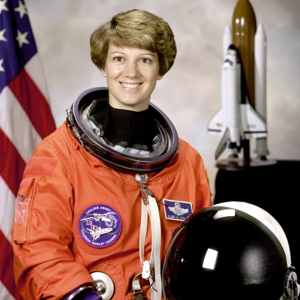

Predicted facial expression: happy
Assistant: Would you like to keep going?


In [5]:
classes = ("angry", "disgust", "fearful", "happy", "neutral", "sad", "surprised")
prompts = {
    "angry": "Would you like a pause or a different approach?",
    "disgust": "Would you like to switch topics?",
    "fearful": "Would it help to go one step at a time?",
    "happy": "Would you like to keep going?",
    "neutral": "What would you like to work on next?",
    "sad": "Would you prefer a break or some company?",
    "surprised": "Would you like me to explain that another way?",
}
template = np.float32([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                       [41.5493, 92.3655], [70.7299, 92.2041]])

def expression_assistant(image):
    frame = cv2.cvtColor(np.asarray(ImageOps.contain(image, (960, 960))), cv2.COLOR_RGB2BGR)
    height, width = frame.shape[:2]
    detector.setInputSize((width, height))
    _, faces = detector.detect(frame)
    if faces is None or len(faces) == 0:
        return None, "No face detected. Try a well-lit, front-facing photo."
    if len(faces) > 1:
        return None, "Several faces detected. Crop the photo to one person."
    points = faces[0, 4:14].reshape(5, 2)
    transform, _ = cv2.estimateAffinePartial2D(points, template, method=cv2.LMEDS)
    if transform is None:
        return None, "Could not align the face. Try a different photo."
    crop = cv2.warpAffine(frame, transform, (112, 112))
    blob = cv2.dnn.blobFromImage(crop, 1 / 127.5, mean=(127.5,) * 3, swapRB=True)
    classifier.setInput(blob)
    label = classes[int(classifier.forward().argmax())]
    return label, prompts[label]

portrait = load_rgb(PORTRAIT)
display(ImageOps.contain(portrait, (300, 300)))
expression, reply = expression_assistant(portrait)
if expression:
    print("Predicted facial expression:", expression)
print("Assistant:", reply)

## Check the results
Compare the transcription with the five printed values on the fictional label. The NASA portrait provides a smiling example. Blank and two-person images exercise cases where the assistant should ask for a better input. These examples check behavior on specific images. Estimating accuracy would require a larger labeled evaluation set.

In [6]:
sample = load_rgb("examples/demo-label.png")
expected = {"Medicine": "Demo Tablets", "Strength": "25 mg", "Form": "Tablet",
            "Batch": "LAB720", "Expiry": "2028-06"}
actual = label_fields(read_label(sample))
for name, value in expected.items():
    print(f"{name:9} expected {value:15} read {actual[name]}")
assert actual == expected
blank = Image.new("RGB", (512, 512), "white")
assert not read_label(blank)
assert all(value is None for value in label_fields("").values())
print("Blank label: no transcription or fields.")

single = load_rgb("examples/astronaut.png")
pair = Image.new("RGB", (single.width * 2, single.height))
pair.paste(single)
pair.paste(single, (single.width, 0))
for scene, picture, expected_label in [("Smiling portrait", single, "happy"),
                                        ("Blank frame", blank, None),
                                        ("Two faces", pair, None)]:
    label, reply = expression_assistant(picture)
    print(f"{scene}: {label or 'no prediction'} | {reply}")
    assert label == expected_label
assert "Several faces" in expression_assistant(pair)[1]

Medicine  expected Demo Tablets    read Demo Tablets
Strength  expected 25 mg           read 25 mg
Form      expected Tablet          read Tablet
Batch     expected LAB720          read LAB720
Expiry    expected 2028-06         read 2028-06


Blank label: no transcription or fields.


Smiling portrait: happy | Would you like to keep going?
Blank frame: no prediction | No face detected. Try a well-lit, front-facing photo.
Two faces: no prediction | Several faces detected. Crop the photo to one person.
